
# DSC212 Research Assignment: Modularity on the Karate Club Graph

**Topic:** Recursive spectral modularity partitioning and network metrics

This notebook implements the assignment using the Zachary Karate Club graph. It constructs the modularity matrix, recursively splits communities using the leading eigenvector of the restricted modularity matrix, visualizes every split, computes four NetworkX node metrics, and plots their evolution.

**Method followed from the handout**
- Global modularity matrix: \(B=A-\frac{kk^\top}{2m}\).
- Restricted matrix for a current community \(C\): the block \(B^{(C)}=B[C,C]\).
- If the largest eigenvalue of \(B^{(C)}\) is positive, split by the signs of its leading eigenvector.
- Otherwise, stop splitting that community.
- The sign convention is \(+1\) for positive entries and \(-1\) otherwise.

The metric-evolution plots below use **community-local metrics**: after each iteration, each node's metrics are calculated in the induced subgraph of the community to which it currently belongs. This makes changes caused by the detected community structure visible. A separate global-metric calculation is also included for reference.



## 1. Imports and data

The NetworkX Karate Club graph contains 34 nodes and 78 edges. The `club` node attribute stores the observed faction labels from the historical split; these labels are used only for a final comparison, not by the detection algorithm.


In [1]:

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from collections import defaultdict

np.set_printoptions(precision=4, suppress=True)

G = nx.karate_club_graph()
n = G.number_of_nodes()
m = G.number_of_edges()

print(f"Number of nodes: {n}")
print(f"Number of edges: {m}")
print("Observed club labels:", pd.Series(nx.get_node_attributes(G, "club")).value_counts().to_dict())


Number of nodes: 34
Number of edges: 78
Observed club labels: {'Mr. Hi': 17, 'Officer': 17}



## 2. Construct the modularity matrix

For an undirected graph, \(A\) is symmetric and \(k_i\) is the degree of node \(i\). The modularity matrix is

\[
B_{ij}=A_{ij}-\frac{k_i k_j}{2m}.
\]

The full modularity matrix is real and symmetric, so its eigenvalues are real. The all-ones vector is an eigenvector with eigenvalue zero.


In [2]:

nodes = list(G.nodes())
A = nx.to_numpy_array(G, nodelist=nodes, dtype=float)
degrees = A.sum(axis=1)
B = A - np.outer(degrees, degrees) / (2 * m)

print("Adjacency matrix shape:", A.shape)
print("Modularity matrix shape:", B.shape)
print("Maximum symmetry error:", np.max(np.abs(B - B.T)))
print("||B 1|| (should be close to 0):", np.linalg.norm(B @ np.ones(n)))


Adjacency matrix shape: (34, 34)
Modularity matrix shape: (34, 34)
Maximum symmetry error: 0.0
||B 1|| (should be close to 0): 204.8657664143053



## 3. Recursive spectral modularity partitioning

For each current community, take the corresponding rows and columns of the **original global** modularity matrix. Find its largest eigenvalue and eigenvector. A positive leading eigenvalue permits a split; otherwise the community is retained.

The algorithm records each successful split and each stopping test. The original graph is not modified.


In [3]:

def recursive_spectral_partition(B_global, node_list, tol=1e-10):
    """Recursively split node groups using restricted blocks of B_global.

    Returns:
        final_communities: list of node lists
        split_history: records for each successful split
        test_history: records for every eigenvalue test
    """
    communities = [list(node_list)]
    split_history = []
    test_history = []
    next_community_id = 0

    # Process communities in a deterministic breadth-first order.
    queue = [list(node_list)]
    while queue:
        current = queue.pop(0)
        idx = [node_list.index(v) for v in current]
        Bc = B_global[np.ix_(idx, idx)]

        # eigh is appropriate because the restricted matrix is symmetric.
        eigenvalues, eigenvectors = np.linalg.eigh(Bc)
        leading_value = float(eigenvalues[-1])
        leading_vector = eigenvectors[:, -1]

        test_history.append({
            "nodes": current.copy(),
            "size": len(current),
            "leading_eigenvalue": leading_value
        })

        if leading_value <= tol or len(current) < 2:
            continue

        plus = [v for v, x in zip(current, leading_vector) if x > 0]
        minus = [v for v, x in zip(current, leading_vector) if x <= 0]

        # A sign split must produce two nonempty groups.
        if not plus or not minus:
            continue

        split_history.append({
            "parent": current.copy(),
            "plus": plus.copy(),
            "minus": minus.copy(),
            "leading_eigenvalue": leading_value,
            "eigenvector": leading_vector.copy()
        })

        # Replace the parent by its two children in the active partition.
        communities.remove(current)
        communities.extend([plus, minus])
        queue.extend([plus, minus])

    # Sort communities by their smallest node for reproducible display.
    communities.sort(key=lambda c: min(c))
    return communities, split_history, test_history


communities, split_history, test_history = recursive_spectral_partition(B, nodes)

print("Number of successful splits:", len(split_history))
print("Number of final communities:", len(communities))
print("Final community sizes:", [len(c) for c in communities])
print("Final communities:")
for i, community in enumerate(communities, start=1):
    print(f"  Community {i}: {sorted(community)}")


Number of successful splits: 12
Number of final communities: 13
Final community sizes: [3, 3, 1, 3, 5, 2, 4, 1, 3, 1, 2, 4, 2]
Final communities:
  Community 1: [0, 11, 17]
  Community 2: [1, 19, 21]
  Community 3: [2]
  Community 4: [3, 7, 12]
  Community 5: [4, 5, 6, 10, 16]
  Community 6: [8, 30]
  Community 7: [9, 18, 22, 33]
  Community 8: [13]
  Community 9: [14, 20, 32]
  Community 10: [15]
  Community 11: [23, 27]
  Community 12: [24, 25, 28, 31]
  Community 13: [26, 29]



## 4. Visualize the graph after every split

A fixed spring layout is used throughout so that node positions remain comparable between iterations. Nodes in the same current community share a color, and every node is labelled by its ID.


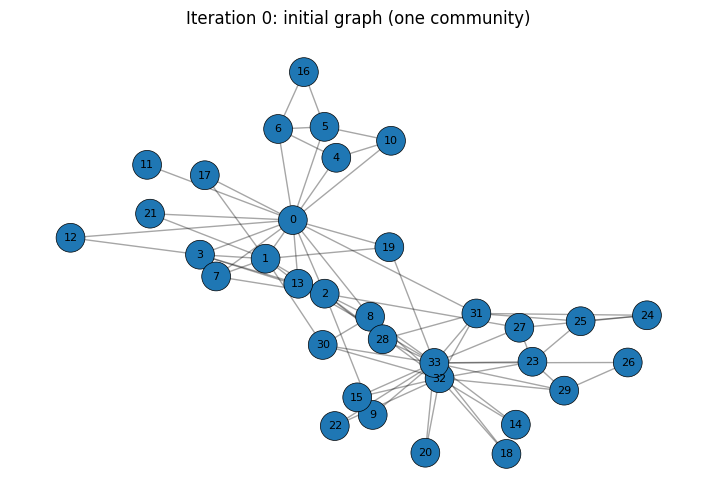

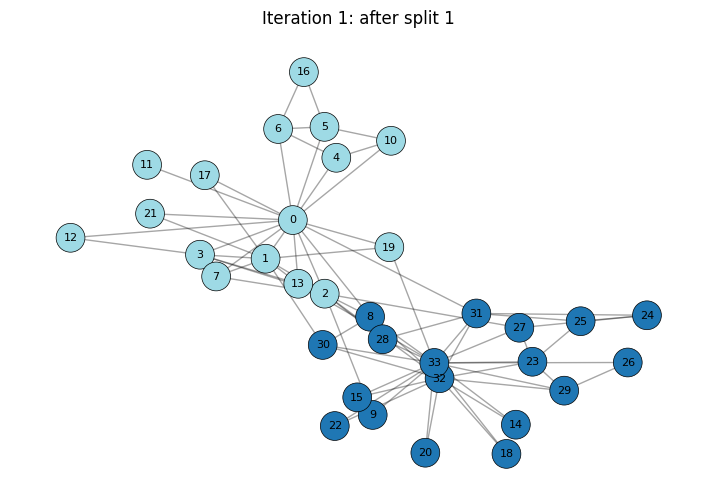

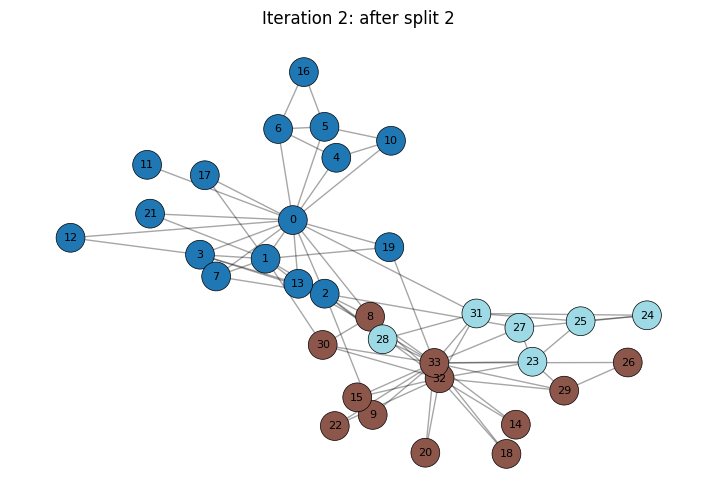

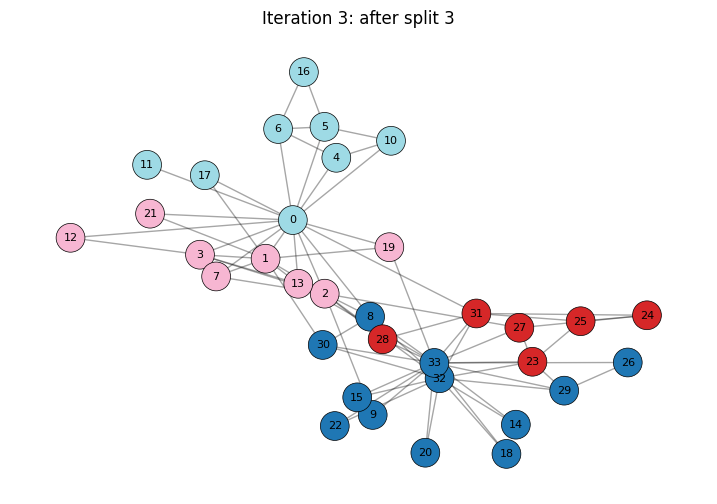

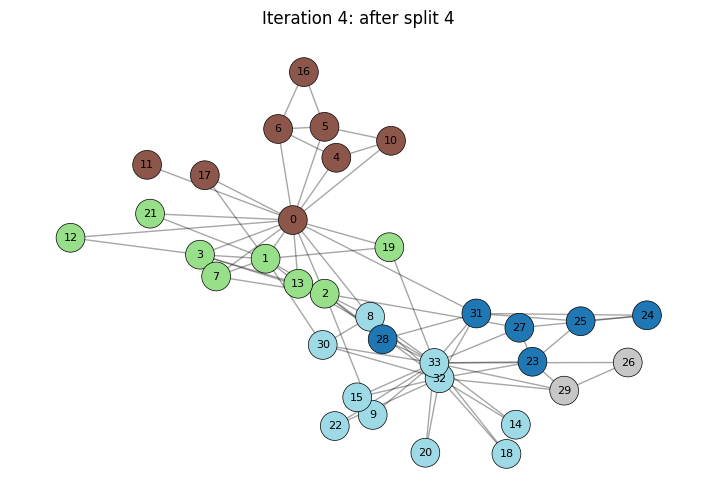

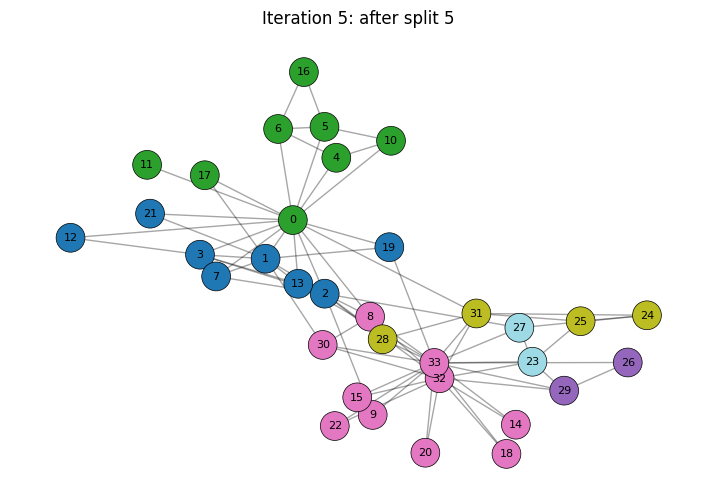

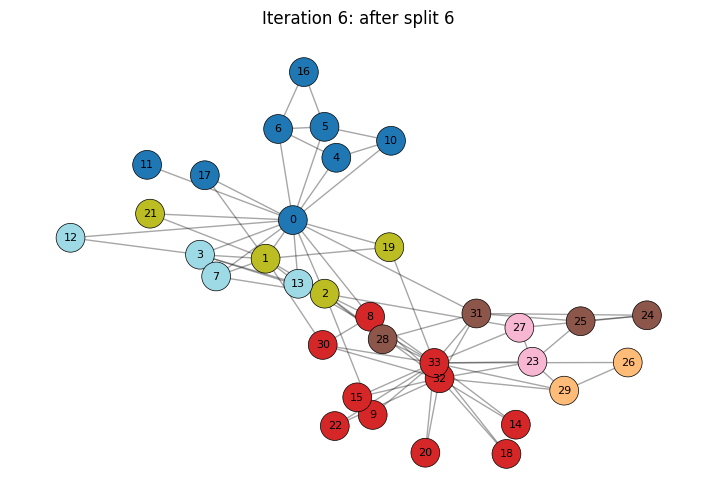

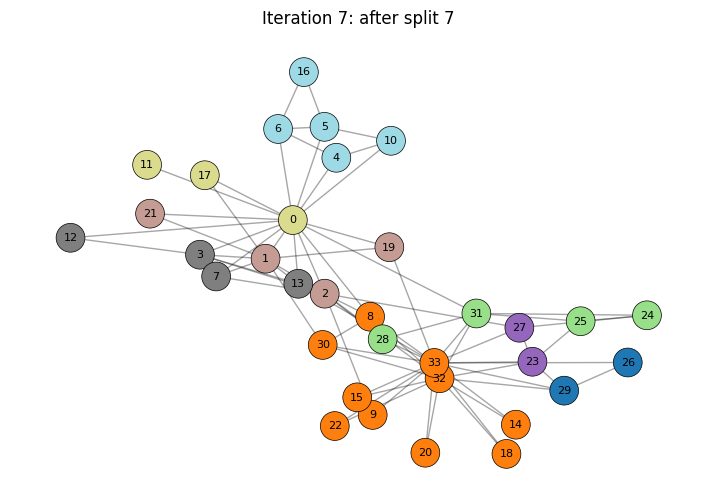

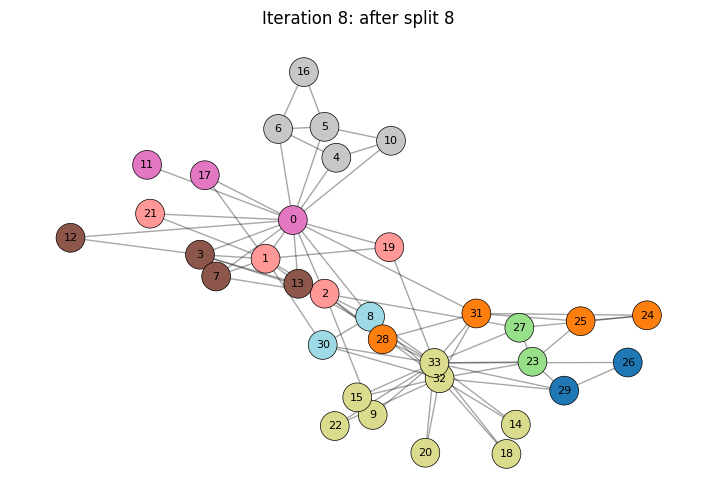

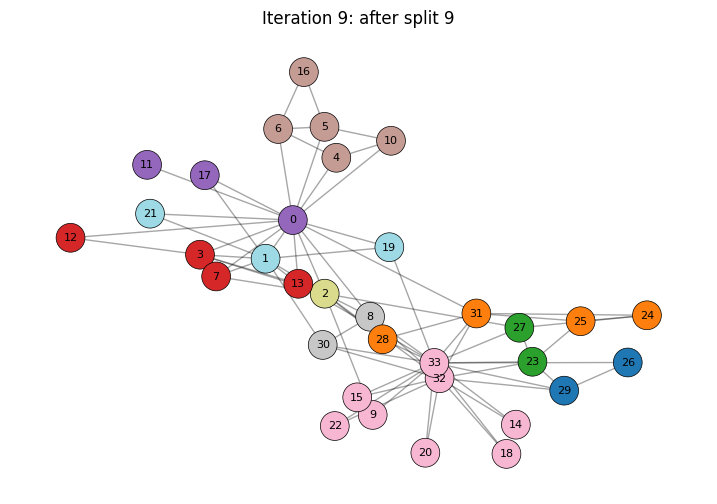

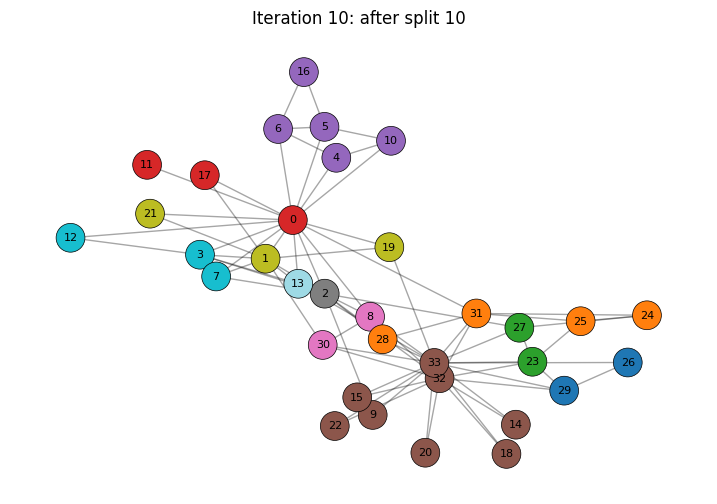

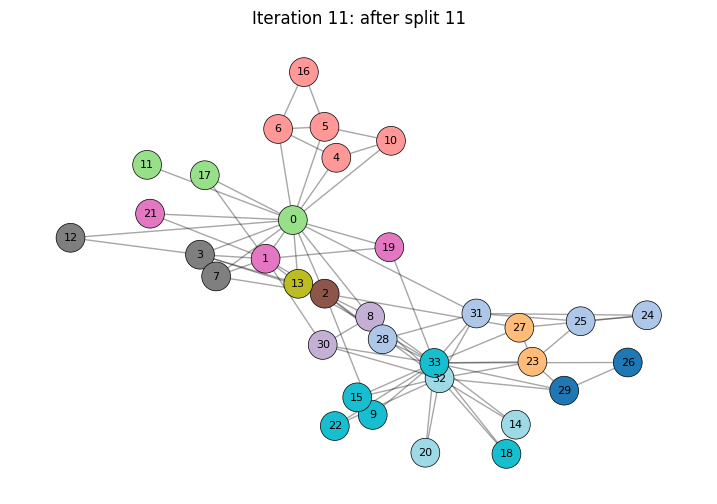

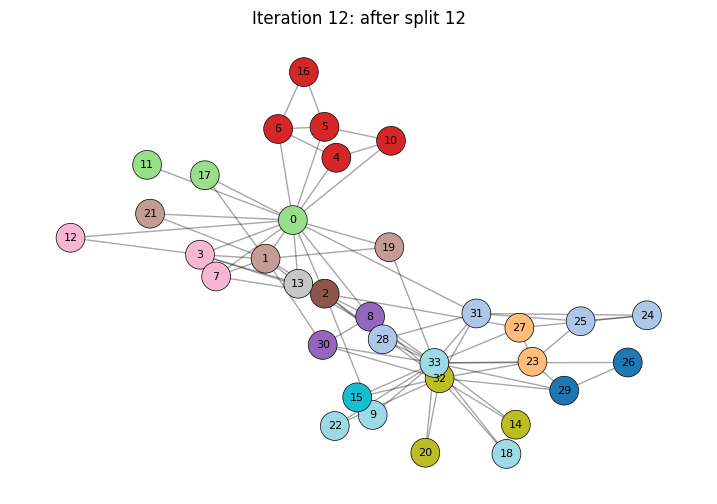

In [4]:

pos = nx.spring_layout(G, seed=42)

def draw_partition(graph, partition, title, positions=pos):
    node_to_community = {}
    for community_id, community in enumerate(partition):
        for node in community:
            node_to_community[node] = community_id

    colors = [node_to_community[v] for v in graph.nodes()]
    plt.figure(figsize=(9, 6))
    nx.draw_networkx_edges(graph, positions, alpha=0.35, width=1.0)
    nx.draw_networkx_nodes(
        graph, positions, node_color=colors, cmap=plt.cm.tab20,
        node_size=430, edgecolors="black", linewidths=0.5
    )
    nx.draw_networkx_labels(graph, positions, font_size=8)
    plt.title(title)
    plt.axis("off")
    plt.show()

# Iteration 0: the whole graph is one community.
partition_at_step = [list(nodes)]
draw_partition(G, partition_at_step, "Iteration 0: initial graph (one community)")

# Replay each split in the order it was found.
for step, record in enumerate(split_history, start=1):
    parent = record["parent"]
    partition_at_step = [c for c in partition_at_step if c != parent]
    partition_at_step.extend([record["plus"], record["minus"]])
    draw_partition(G, partition_at_step, f"Iteration {step}: after split {step}")



## 5. Compute node metrics after each split

For each iteration, metrics are recalculated on each community's induced subgraph:
1. Degree centrality
2. Betweenness centrality
3. Closeness centrality
4. Clustering coefficient

For nodes in a community of size one, degree, betweenness, closeness and clustering are defined here as zero. This avoids undefined values and keeps every node represented in every iteration.


In [5]:

def metrics_within_partition(graph, partition):
    """Calculate each node's metrics inside its current community subgraph."""
    result = {}
    for community in partition:
        H = graph.subgraph(community).copy()
        if len(H) <= 1:
            local = {
                v: {"degree": 0.0, "betweenness": 0.0,
                    "closeness": 0.0, "clustering": 0.0}
                for v in H.nodes()
            }
        else:
            d = nx.degree_centrality(H)
            b = nx.betweenness_centrality(H)
            c = nx.closeness_centrality(H)
            cl = nx.clustering(H)
            local = {
                v: {"degree": d[v], "betweenness": b[v],
                    "closeness": c[v], "clustering": cl[v]}
                for v in H.nodes()
            }
        result.update(local)
    return result


partition_history = [[list(nodes)]]
current_partition = [list(nodes)]
for record in split_history:
    current_partition = [c for c in current_partition if c != record["parent"]]
    current_partition.extend([record["plus"], record["minus"]])
    partition_history.append([c.copy() for c in current_partition])

metric_names = ["degree", "betweenness", "closeness", "clustering"]
metric_history = {metric: [] for metric in metric_names}

for iteration, partition in enumerate(partition_history):
    values = metrics_within_partition(G, partition)
    for metric in metric_names:
        metric_history[metric].append({v: values[v][metric] for v in nodes})

print(f"Metric snapshots recorded: {len(partition_history)} (iterations 0 to {len(partition_history)-1})")


Metric snapshots recorded: 13 (iterations 0 to 12)



## 6. Plot metric evolution for every node

Each line represents one node. The horizontal axis is the iteration number, beginning with the unsplit graph at iteration 0.


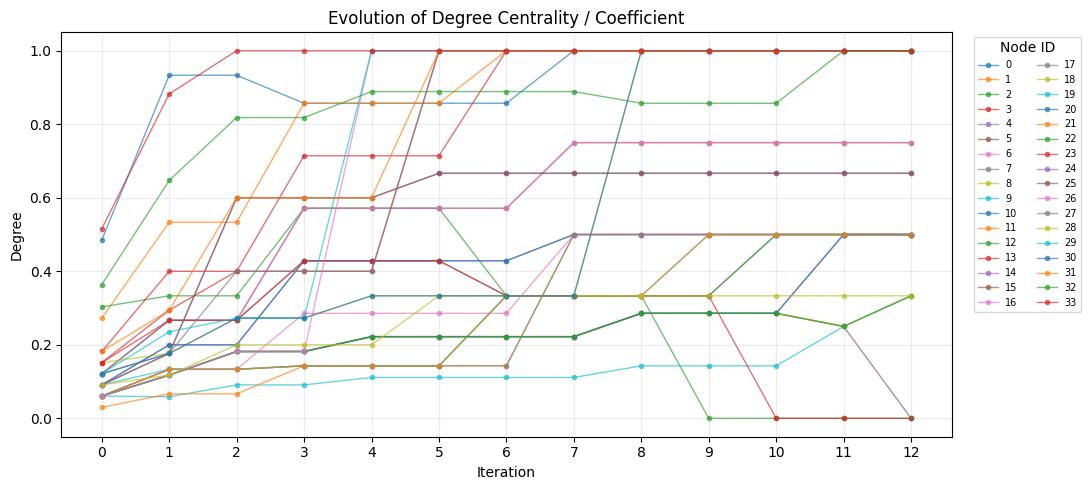

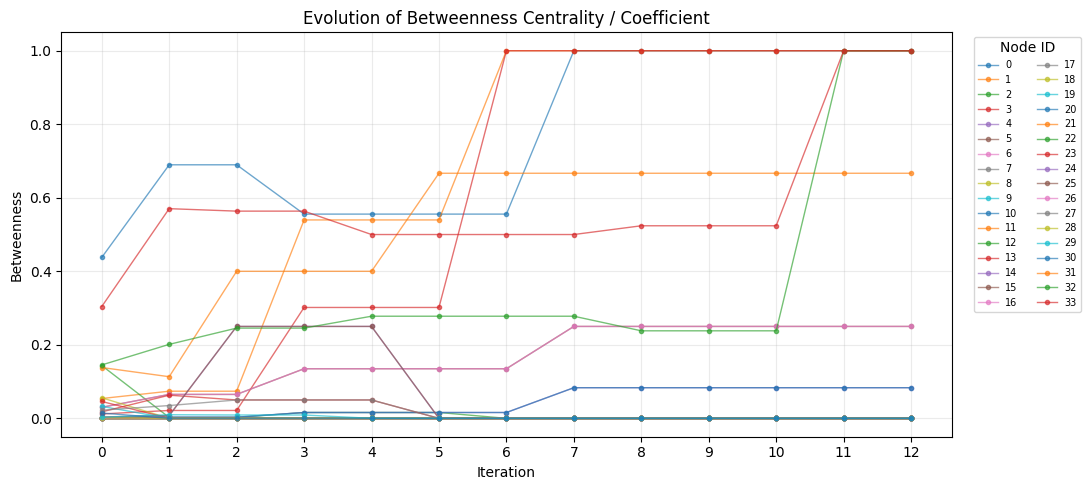

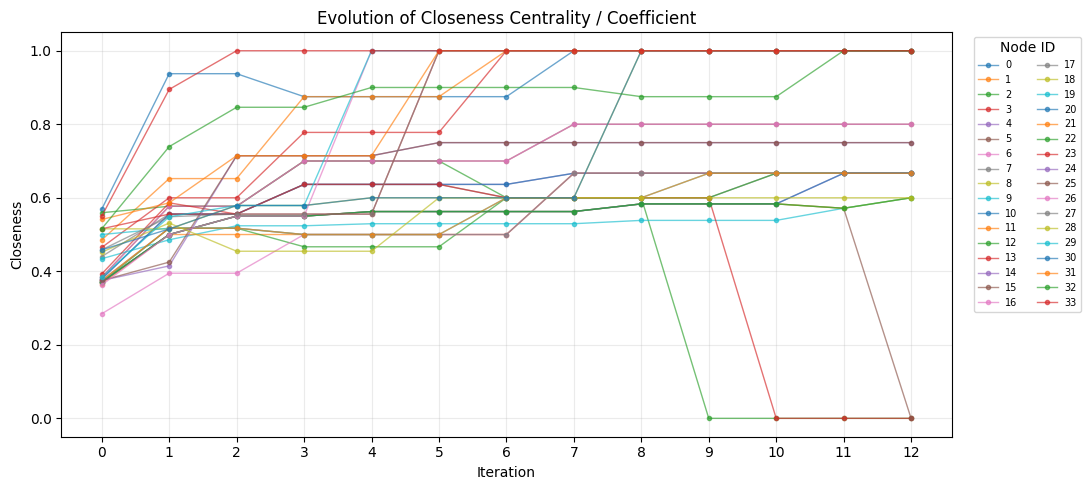

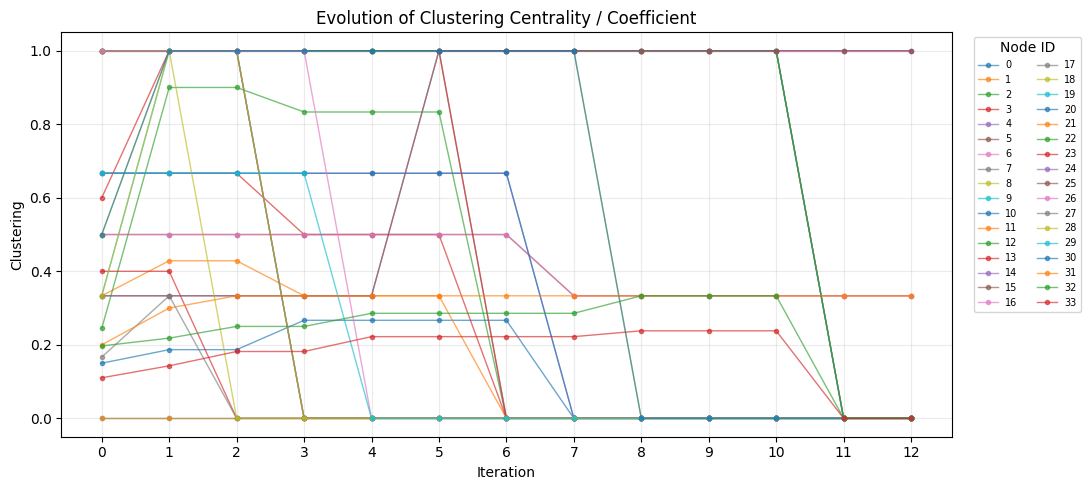

In [6]:

for metric in metric_names:
    plt.figure(figsize=(11, 5))
    for v in nodes:
        y = [snapshot[v] for snapshot in metric_history[metric]]
        plt.plot(range(len(y)), y, marker="o", markersize=3, linewidth=1, alpha=0.65, label=str(v))
    plt.title(f"Evolution of {metric.capitalize()} Centrality / Coefficient")
    plt.xlabel("Iteration")
    plt.ylabel(metric.capitalize())
    plt.xticks(range(len(partition_history)))
    plt.grid(alpha=0.25)
    plt.legend(title="Node ID", bbox_to_anchor=(1.02, 1), loc="upper left",
               ncol=2, fontsize=7)
    plt.tight_layout()
    plt.show()



## 7. Metric tables and global reference metrics

The following table reports the final community-local metrics. For comparison, the global metrics are calculated once on the original full graph. Global metrics do not change during partitioning because the underlying graph \(G\) is unchanged; community-local metrics change because each node is evaluated only against nodes in its current community.


In [7]:

final_local = metrics_within_partition(G, communities)
global_metrics = {
    "degree": nx.degree_centrality(G),
    "betweenness": nx.betweenness_centrality(G),
    "closeness": nx.closeness_centrality(G),
    "clustering": nx.clustering(G)
}

final_table = pd.DataFrame.from_dict(final_local, orient="index")
final_table.index.name = "Node"
final_table = final_table.sort_index()
display(final_table.round(4))

global_table = pd.DataFrame(global_metrics).sort_index()
global_table.index.name = "Node"
print("Global metrics on the original graph:")
display(global_table.round(4))


,degree,betweenness,closeness,clustering
Node,,,,
0,1.0000,1.0000,1.0000,0.0000
1,1.0000,1.0000,1.0000,0.0000
2,0.0000,0.0000,0.0000,0.0000
3,1.0000,1.0000,1.0000,0.0000
4,0.5000,0.0833,0.6667,0.0000
5,0.7500,0.2500,0.8000,0.3333
6,0.7500,0.2500,0.8000,0.3333
7,0.5000,0.0000,0.6667,0.0000
8,1.0000,0.0000,1.0000,0.0000


Global metrics on the original graph:


,degree,betweenness,closeness,clustering
Node,,,,
0,0.4848,0.4376,0.5690,0.1500
1,0.2727,0.0539,0.4853,0.3333
2,0.3030,0.1437,0.5593,0.2444
3,0.1818,0.0119,0.4648,0.6667
4,0.0909,0.0006,0.3793,0.6667
5,0.1212,0.0300,0.3837,0.5000
6,0.1212,0.0300,0.3837,0.5000
7,0.1212,0.0000,0.4400,1.0000
8,0.1515,0.0559,0.5156,0.5000



## 8. Compare detected communities with the observed club factions

The historical `club` attribute is used only for evaluation after detection. Community IDs have no inherent meaning, so the table shows the observed faction counts in each detected community.


In [8]:

club_labels = nx.get_node_attributes(G, "club")
comparison = []
for community_id, community in enumerate(communities, start=1):
    counts = pd.Series([club_labels[v] for v in community]).value_counts().to_dict()
    comparison.append({
        "Detected community": community_id,
        "Size": len(community),
        "Mr. Hi faction": counts.get("Mr. Hi", 0),
        "Officer faction": counts.get("Officer", 0)
    })
display(pd.DataFrame(comparison))


,Detected community,Size,Mr. Hi faction,Officer faction
0,1,3,3,0
1,2,3,3,0
2,3,1,1,0
3,4,3,3,0
4,5,5,5,0
5,6,2,1,1
6,7,4,0,4
7,8,1,1,0
8,9,3,0,3
9,10,1,0,1



## 9. Discussion

### Recursive spectral partitioning
The algorithm begins with all 34 nodes in one group. At each step it forms the restricted modularity matrix for a current group and computes its largest eigenpair. A positive leading eigenvalue indicates that a positive quadratic direction exists, so the leading eigenvector is thresholded by sign to obtain two groups. Recursion ends for a group when its leading eigenvalue is nonpositive (up to the numerical tolerance used in the code).

### Central nodes and the effect of communities
In the original Karate Club graph, nodes with high global degree centrality have many direct connections. Betweenness highlights nodes that lie on many shortest paths and therefore act as bridges. Closeness measures how quickly a node can reach the rest of the graph. Clustering measures how interconnected a node's neighbours are.

After partitioning, community-local metrics are computed within each induced community. A node may lose degree, betweenness, or closeness when many of its original neighbours lie in other communities. A node can remain locally important if it has many connections or shortest-path roles inside its own group. Clustering may increase or decrease depending on whether the node's neighbours remain mutually connected within the same community.

### Nodes that remain important
Use the global metric table and the metric-evolution plots to identify nodes that retain high values. High-degree nodes are not necessarily the highest-betweenness nodes: a node with fewer links can still be an important bridge if many shortest paths pass through it. The plots provide the evidence for discussing which nodes remain central in the detected groups.

### Limitations
This is a greedy recursive method: each split is decided locally from the leading eigenvector, and later steps do not revisit earlier splits. Thresholding a continuous eigenvector by sign is a heuristic for the discrete optimization problem. The resulting partition can depend on the graph and numerical eigenvector details. The method is intended as an educational implementation of the handout's algorithm, not a guarantee of the globally optimal modularity partition.



## 10. Conclusion

This assignment implemented spectral modularity community detection on the Karate Club graph. The modularity matrix compares observed adjacency with the degree-preserving random baseline. The leading eigenvector provides a relaxed direction for a bipartition, and recursive use of restricted modularity blocks produces multiple communities. Visualizations show the partition at each successful split, while metric-evolution plots show how each node's role changes when metrics are evaluated within its current community.

## References

1. M. E. J. Newman, “Modularity and community structure in networks,” *Proceedings of the National Academy of Sciences*, 103(23), 8577–8582, 2006.
2. W. W. Zachary, “An Information Flow Model for Conflict and Fission in Small Groups,” *Journal of Anthropological Research*, 33(4), 452–473, 1977.
3. NetworkX documentation, “Zachary’s Karate Club graph” and centrality functions: https://networkx.org/documentation/stable/
